# LAPORAN TUGAS UJIAN TENGAH SEMESTER (UTS) GRAF SAINS DATA
## Analisis Graf Bipartite, Vector Space Modelling (VSM), dan Sistem Rekomendasi Collaborative Filtering KNN pada Dataset E-Commerce RetailRocket Menggunakan Neo4J dan Python

---

### **Identitas Mahasiswa & Pembagian Data Periode (Fold)**

| Atribut | Informasi Mahasiswa |
| :--- | :--- |
| **Nama Lengkap** | **MOCH. AKBAR HANAFI** |
| **Nomor Induk Mahasiswa (NIM)** | **23031554018** |
| **Nomor Urut Presensi** | **3** |
| **Kelas** | **GSD 2023E** |
| **Program Studi** | S1 Sains Data |
| **Fakultas / Universitas** | Fakultas Matematika dan Ilmu Pengetahuan Alam — Universitas Negeri Surabaya |
| **Mata Kuliah** | Graf Sains Data (3 SKS) — Gasal 2026/2027 |
| **Fold Training (P1)** | `2015-05-03 00:00:00 UTC` s/d `2015-07-22 23:59:59 UTC` (`1430611200000` ms s/d `1437609599999` ms) |
| **Fold Testing (P2)** | `2015-07-23 00:00:00 UTC` s/d `2015-08-12 23:59:59 UTC` (`1437609600000` ms s/d `1439423999999` ms) |

---

### Apa saja yang dikerjakan di notebook ini

1. Menyiapkan virtual environment dan memastikan koneksi ke Neo4j lewat driver Python sudah jalan.
2. Menjawab tiga pertanyaan checkpoint tugas pendahuluan, sekalian mencoba membuat node `Person` dan relasi `KNOWS`.
3. Menyaring `events.csv` berdasarkan dua periode yang sudah ditentukan untuk saya, lalu menyimpannya ke file CSV terpisah.
4. Memilih satu user target secara acak (pakai seed supaya hasilnya tetap sama kalau dijalankan ulang), membangun subgraph di sekitar user itu, lalu mengimpornya ke Neo4j.
5. Menghitung komposisi simpul dan relasi subgraph lewat Python API, lengkap dengan penjelasan query Cypher-nya.
6. Membuat representasi VSM untuk sisi User dan sisi Item beserta plot NetworkX-nya, lalu membandingkan proyeksi mana yang lebih masuk akal dipakai.
7. Menghitung cosine similarity terhadap user target, menuliskannya kembali ke graf sebagai relasi `SIMILAR`, dan membandingkan kondisi graf sebelum dan sesudahnya.
8. Membuat rekomendasi collaborative filtering KNN dengan k = 5, lalu mengukurnya dengan Hit@5 dan NDCG@5 terhadap periode testing.

---
## **1. Tugas Pendahuluan**

### **1.1 Persiapan dan Perkenalan Lingkungan**
Virtual environment dibuat menggunakan `uv` atau `python -m venv` untuk memastikan isolasi dependensi. Seluruh library yang dibutuhkan dicatat dalam `requirements.txt`.

In [1]:
# Memeriksa versi library yang terpasang dalam virtual environment
import sys
import neo4j
import pandas as pd
import numpy as np
import sklearn
import networkx as nx
import matplotlib

print(f"Python Interpreter : {sys.executable}")
print(f"Python Version     : {sys.version.split()[0]}")
print(f"Neo4j Driver       : {neo4j.__version__}")
print(f"Pandas Version     : {pd.__version__}")
print(f"NumPy Version      : {np.__version__}")
print(f"Scikit-Learn       : {sklearn.__version__}")
print(f"NetworkX Version   : {nx.__version__}")
print(f"Matplotlib Version : {matplotlib.__version__}")

Python Interpreter : /Users/macairm12020/college/UTS GRAF/myvenv/bin/python
Python Version     : 3.12.15
Neo4j Driver       : 6.4.1
Pandas Version     : 3.1.0
NumPy Version      : 2.5.4
Scikit-Learn       : 1.9.1
NetworkX Version   : 3.7
Matplotlib Version : 3.11.2


### **1.2 Mempelajari Penggunaan Driver Neo4J**

Berikut adalah implementasi fungsi koneksi driver Neo4j, pembuatan node `Person` beserta relasi `KNOWS`, dan pembacaan kembali menggunakan `RoutingControl.READ`.

In [2]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "password123")

def add_friend(driver, name, friend_name):
    query = (
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)"
    )
    driver.execute_query(
        query,
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )

def print_friends(driver, name):
    query = (
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name"
    )
    records, _, _ = driver.execute_query(
        query,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )
    friends = [record["friend.name"] for record in records]
    return friends

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    # Tambahkan relasi pertemanan Arthur
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    
    friends_of_arthur = print_friends(driver, "Arthur")
    print("Daftar teman dari Arthur yang tercatat di Neo4j:")
    for f in friends_of_arthur:
        print(f" - {f}")

Daftar teman dari Arthur yang tercatat di Neo4j:
 - Guinevere
 - Lancelot
 - Merlin


#### **Jawaban Pertanyaan Pendahuluan (Checkpoint)**

1. **Apa nama database yang digunakan pada tutorial ini?**
   - **Jawaban:** Database yang digunakan adalah **`neo4j`**, yang merupakan *default database* pada instalasi Neo4J Enterprise / Community Edition (dinyatakan secara eksplisit dalam argumen `database_="neo4j"` pada pemanggilan `execute_query`).

2. **Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**
   - **Jawaban:**
     - **Klausul Cypher `USE <database_name>`:** Digunakan di awal kueri untuk mengarahkan eksekusi kueri ke database tertentu, contoh:
       ```cypher
       USE retaildb MATCH (v:Visitor) RETURN count(v);
       ```
     - **Manajemen Database Administratif via Database `system`:**
       ```cypher
       SHOW DATABASES;
       CREATE DATABASE salesdb;
       STOP DATABASE salesdb;
       ```
     - **Konfigurasi Python Driver Session:** Mengarahkan session atau transaksi ke database target secara dinamis via parameter:
       ```python
       with driver.session(database="salesdb") as session:
           session.run("MATCH (n) RETURN n LIMIT 10")
       ```

3. **Apa jenis graf pertemanan yang telah dibuat di sini?**
   - **Jawaban:** Graf yang dibuat adalah **Directed Graph (Graf Berarah)**, karena relasi didefinisikan secara asimetris dengan tanda panah spesifik: `(a:Person)-[:KNOWS]->(friend:Person)`. Artinya, `Arthur KNOWS Guinevere` tidak secara otomatis membuat `Guinevere KNOWS Arthur` kecuali relasi balasan dibuat secara eksplisit.

#### **CYPHER Total Reset**
Melakukan pembersihan seluruh simpul dan relasi percobaan dari database sebelum mengimpor data utama.

In [3]:
# Melakukan reset total database Neo4j
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n;", database_="neo4j")
    records, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS total", database_="neo4j")
    print(f"Total node setelah reset: {records[0]['total']}")

Total node setelah reset: 0


---
## **2. Soal UTS**

### **2.1 Wrangling dan EDA**

#### **2.1.1 & 2.1.2 Penentuan Periode Filter Timestamp dan Penyimpanan CSV**
Sesuai rincian identitas mahasiswa **MOCH. AKBAR HANAFI (NIM: 23031554018)**:
- **Fold Training (P1):** `2015-05-03 00:00:00 UTC` s/d `2015-07-22 23:59:59 UTC` (Epoch ms: `1430611200000` s/d `1437609599999`)
- **Fold Testing (P2):** `2015-07-23 00:00:00 UTC` s/d `2015-08-12 23:59:59 UTC` (Epoch ms: `1437609600000` s/d `1439423999999`)

In [4]:
# Membaca dataset RetailRocket dan memfilter data berdasarkan Fold Mahasiswa
p1_start, p1_end = 1430611200000, 1437609599999
p2_start, p2_end = 1437609600000, 1439423999999

df_raw = pd.read_csv("data/events.csv")
print(f"Total baris data mentah events.csv: {len(df_raw):,}")

# Filter Fold Training (P1)
df_p1 = df_raw[(df_raw["timestamp"] >= p1_start) & (df_raw["timestamp"] <= p1_end)].copy()
# Filter Fold Testing (P2)
df_p2 = df_raw[(df_raw["timestamp"] >= p2_start) & (df_raw["timestamp"] <= p2_end)].copy()

print(f"Fold Training (P1) : {len(df_p1):,} baris | {df_p1['visitorid'].nunique():,} unique visitors | {df_p1['itemid'].nunique():,} unique items")
print(f"Fold Testing (P2)  : {len(df_p2):,} baris | {df_p2['visitorid'].nunique():,} unique visitors | {df_p2['itemid'].nunique():,} unique items")

# Irisan pengunjung pada kedua fold
common_visitors = set(df_p1["visitorid"]).intersection(set(df_p2["visitorid"]))
print(f"Pengunjung yang aktif pada P1 dan P2 : {len(common_visitors):,} visitors")

Total baris data mentah events.csv: 2,756,101
Fold Training (P1) : 1,681,206 baris | 853,619 unique visitors | 190,283 unique items
Fold Testing (P2)  : 433,774 baris | 240,844 unique visitors | 97,869 unique items


Pengunjung yang aktif pada P1 dan P2 : 18,144 visitors


Berkas hasil filter disimpan ke dalam direktori `data/` sebagai berkas CSV mandiri:
- `data/events_p1_train.csv` : Data lengkap Fold Training P1 (1.681.206 baris)
- `data/events_p2_test.csv` : Data lengkap Fold Testing P2 (433.774 baris)
- `data/events_subgraph.csv` : Data komunitas subgraph aktif yang diimpor ke Neo4j (25.886 baris)

In [5]:
# Memeriksa keberadaan file CSV yang tersimpan
import os
for fname in ["events_p1_train.csv", "events_p2_test.csv", "events_subgraph.csv"]:
    fpath = os.path.join("data", fname)
    fsize = os.path.getsize(fpath) / (1024 * 1024)
    print(f"File: {fpath:<25} | Ukuran: {fsize:.2f} MB")

File: data/events_p1_train.csv  | Ukuran: 54.84 MB
File: data/events_p2_test.csv   | Ukuran: 14.16 MB
File: data/events_subgraph.csv  | Ukuran: 0.86 MB


#### **Pemilihan User Target dan Pembentukan Subgraph**

Sebelum masuk ke Neo4j, saya tentukan dulu user mana yang jadi fokus analisis. Data P1 terlalu besar untuk diimpor seluruhnya (1,68 juta baris dari 853 ribu user), jadi yang diimpor cukup lingkungan interaksi di sekitar user target saja.

Pemilihannya acak tapi tetap bisa diulang: seed ditetapkan di awal, dan kandidatnya dibatasi pada user yang aktif di kedua periode (P1 dan P2) dengan minimal 15 interaksi di P1. Syarat ini perlu karena user tanpa aktivitas di P2 tidak punya ground truth, jadi Hit@5 dan NDCG@5-nya tidak bisa dihitung nanti.

In [6]:
# Pemilihan user target secara acak yang bisa direproduksi (Soal 2.2.1)
import numpy as np

SEED = 732
np.random.seed(SEED)

freq_p1 = df_p1.groupby("visitorid").size()
aktif_dua_periode = set(df_p1["visitorid"]) & set(df_p2["visitorid"])
kandidat = sorted([u for u in aktif_dua_periode if freq_p1.loc[u] >= 15])

target_user = int(np.random.choice(kandidat))

print(f"User aktif di P1 dan P2          : {len(aktif_dua_periode):,}")
print(f"Kandidat (min. 15 interaksi P1)  : {len(kandidat):,}")
print(f"Seed yang dipakai                : {SEED}")
print(f"User target terpilih             : {target_user}")
print(f"Jumlah interaksi di P1           : {len(df_p1[df_p1['visitorid'] == target_user])} baris")
print(f"Jumlah interaksi di P2           : {len(df_p2[df_p2['visitorid'] == target_user])} baris")

User aktif di P1 dan P2          : 18,144
Kandidat (min. 15 interaksi P1)  : 1,116
Seed yang dipakai                : 732
User target terpilih             : 1293068
Jumlah interaksi di P1           : 19 baris
Jumlah interaksi di P2           : 12 baris


Subgraph-nya dibangun sebagai lingkungan dua langkah di sekitar user target: ambil semua item yang pernah disentuh user target, lalu ambil semua user lain yang juga menyentuh item-item tersebut, kemudian ambil seluruh interaksi milik user-user itu di P1.

Alasannya sederhana. Rekomendasi KNN nantinya bergantung pada tetangga yang punya irisan item dengan user target. User yang sama sekali tidak pernah menyentuh item yang sama pasti punya cosine similarity nol, jadi tidak ada gunanya ikut diimpor dan dihitung.

In [7]:
# Membangun subgraph dua langkah di sekitar user target, lalu menyimpannya ke CSV
item_target = set(df_p1[df_p1["visitorid"] == target_user]["itemid"])
tetangga = set(df_p1[df_p1["itemid"].isin(item_target)]["visitorid"])

sub_df = df_p1[df_p1["visitorid"].isin(tetangga)].copy()
sub_df.to_csv("data/events_subgraph.csv", index=False)

print(f"Item yang disentuh user target : {len(item_target)}")
print(f"User dalam subgraph            : {sub_df['visitorid'].nunique():,}")
print(f"Item dalam subgraph            : {sub_df['itemid'].nunique():,}")
print(f"Total baris interaksi          : {len(sub_df):,}")
print("\nKomposisi jenis interaksi:")
print(sub_df["event"].value_counts().to_string())

Item yang disentuh user target : 8
User dalam subgraph            : 374
Item dalam subgraph            : 9,137
Total baris interaksi          : 25,886

Komposisi jenis interaksi:
event
view           23349
addtocart       1482
transaction     1055


#### **2.1.3 Komposisi Subgraph pada Neo4J dan Penjelasan Kueri Cypher**

Subgraph yang sudah dibentuk di atas diimpor ke Neo4j memakai mekanisme batch langsung di bawah ini. Setelah itu, komposisi simpul dan relasinya dibaca kembali lewat Python API supaya terlihat isi graf yang sebenarnya tersimpan di database.

In [8]:
# Mengimpor subgraph ke Neo4j dengan mekanisme batch
def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT unique_visitor_id IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE;"
    )
    session.run(
        "CREATE CONSTRAINT unique_item_id IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE;"
    )

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        RETURN count(*) AS cnt

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        RETURN count(*) AS cnt

        UNION ALL

        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
        RETURN count(*) AS cnt
    }
    RETURN count(*) AS total
    """
    tx.run(cypher_query, batch=batch)

records = sub_df.copy()
records["transactionid"] = records["transactionid"].fillna("").astype(str)
records = records.to_dict(orient="records")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        create_constraints(session)
        for i in range(0, len(records), 1000):
            session.execute_write(import_batch, records[i:i + 1000])

print(f"Selesai mengimpor {len(records):,} baris interaksi ke Neo4j.")


/var/folders/tc/6qqbhtsd3cx34rphzrhr6sxr0000gp/T/ipykernel_47991/2289725708.py:40: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  records["transactionid"] = records["transactionid"].fillna("").astype(str)


Selesai mengimpor 25,886 baris interaksi ke Neo4j.


In [9]:
# Query komposisi simpul dan relasi dari database Neo4j
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    # 1. Komposisi Node
    node_query = '''
    MATCH (n)
    RETURN labels(n)[0] AS nodeType, count(n) AS nodeCount
    ORDER BY nodeCount DESC
    '''
    node_records, _, _ = driver.execute_query(node_query, database_="neo4j")
    
    # 2. Komposisi Relasi
    rel_query = '''
    MATCH ()-[r]->()
    RETURN type(r) AS relType, count(r) AS relCount
    ORDER BY relCount DESC
    '''
    rel_records, _, _ = driver.execute_query(rel_query, database_="neo4j")

print("=== Komposisi Simpul (Nodes) Subgraph Neo4J ===")
for r in node_records:
    print(f" - Simpul [{r['nodeType']:<10}]: {r['nodeCount']:,} node")

print("\n=== Komposisi Hubungan (Relationships) Subgraph Neo4J ===")
for r in rel_records:
    print(f" - Relasi [:{r['relType']:<15}]: {r['relCount']:,} relasi")

=== Komposisi Simpul (Nodes) Subgraph Neo4J ===
 - Simpul [Item      ]: 9,137 node
 - Simpul [Visitor   ]: 374 node

=== Komposisi Hubungan (Relationships) Subgraph Neo4J ===
 - Relasi [:VIEWED         ]: 23,349 relasi
 - Relasi [:ADDED_TO_CART  ]: 1,482 relasi
 - Relasi [:BOUGHT         ]: 1,055 relasi


**Penjelasan Kueri CYPHER yang Digunakan:**
1. **Query Komposisi Simpul:**
   ```cypher
   MATCH (n)
   RETURN labels(n)[0] AS nodeType, count(n) AS nodeCount
   ORDER BY nodeCount DESC;
   ```
   *Penjelasan:* Pola `MATCH (n)` mencocokkan setiap simpul dalam graf. Fungsi `labels(n)[0]` mengekstrak label utama simpul (`Visitor` atau `Item`). Fungsi agregasi `count(n)` menghitung total instance per label, dan diurutkan secara menurun (`ORDER BY DESC`).

2. **Query Komposisi Relasi:**
   ```cypher
   MATCH ()-[r]->()
   RETURN type(r) AS relType, count(r) AS relCount
   ORDER BY relCount DESC;
   ```
   *Penjelasan:* Pola `()-[r]->()` mencocokkan seluruh relasi terarah tanpa membatasi label simpul asal maupun tujuan. Fungsi `type(r)` mengambil nama tipe relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`, atau `SIMILAR`), lalu `count(r)` menghitung total kemunculan setiap tipe relasi.

#### **2.1.4 Vector Space Modelling (VSM) Simpul User**

Pada representasi VSM Simpul User, setiap **User** dimodelkan sebagai vektor dalam ruang berdimensi item-item yang tersedia.
- **Baris:** User ($v_i \in U$)
- **Kolom:** Item ($item_j \in I$)
- **Nilai Elemen ($M_{u, i}$):** Bobot interaksi e-commerce ($w \in \{1: 	ext{view}, 2: 	ext{addtocart}, 3: 	ext{transaction}\}$).

In [10]:
# Membangun Matriks VSM User-Item
from scipy.sparse import csr_matrix
sub_df = pd.read_csv("data/events_subgraph.csv")

users = sorted(sub_df["visitorid"].unique())
items = sorted(sub_df["itemid"].unique())

n_users = len(users)
n_items = len(items)

user_map = {u: i for i, u in enumerate(users)}
item_map = {it: i for i, it in enumerate(items)}

row_ind = [user_map[u] for u in sub_df["visitorid"]]
col_ind = [item_map[it] for it in sub_df["itemid"]]
weights = sub_df["event"].map({"view": 1.0, "addtocart": 2.0, "transaction": 3.0}).values

mat_user = csr_matrix((weights, (row_ind, col_ind)), shape=(n_users, n_items))

total_elements = n_users * n_items
nnz = mat_user.nnz
sparsity_user = (1.0 - (nnz / total_elements)) * 100

print("=== Karakteristik VSM Simpul User ===")
print(f"Dimensi Matriks (Shape) : ({n_users:,} User, {n_items:,} Item)")
print(f"Jumlah Fitur Dimensi    : {n_items:,} dimensi Item")
print(f"Total Sel Matriks       : {total_elements:,}")
print(f"Elemen Non-Zero (nnz)   : {nnz:,}")
print(f"Sparsity (Tingkat Kerapian): {sparsity_user:.2f}%")
print(f"Rata-rata interaksi per User: {nnz / n_users:.1f} item")

=== Karakteristik VSM Simpul User ===
Dimensi Matriks (Shape) : (374 User, 9,137 Item)
Jumlah Fitur Dimensi    : 9,137 dimensi Item
Total Sel Matriks       : 3,417,238
Elemen Non-Zero (nnz)   : 14,568
Sparsity (Tingkat Kerapian): 99.57%
Rata-rata interaksi per User: 39.0 item


**Visualisasi Plot NetworkX Proyeksi VSM Simpul User:**
Menampilkan graf proyeksi simpul User di mana edge merepresentasikan keterkaitan kemiripan preferensi (Cosine Similarity) antar-pengunjung.

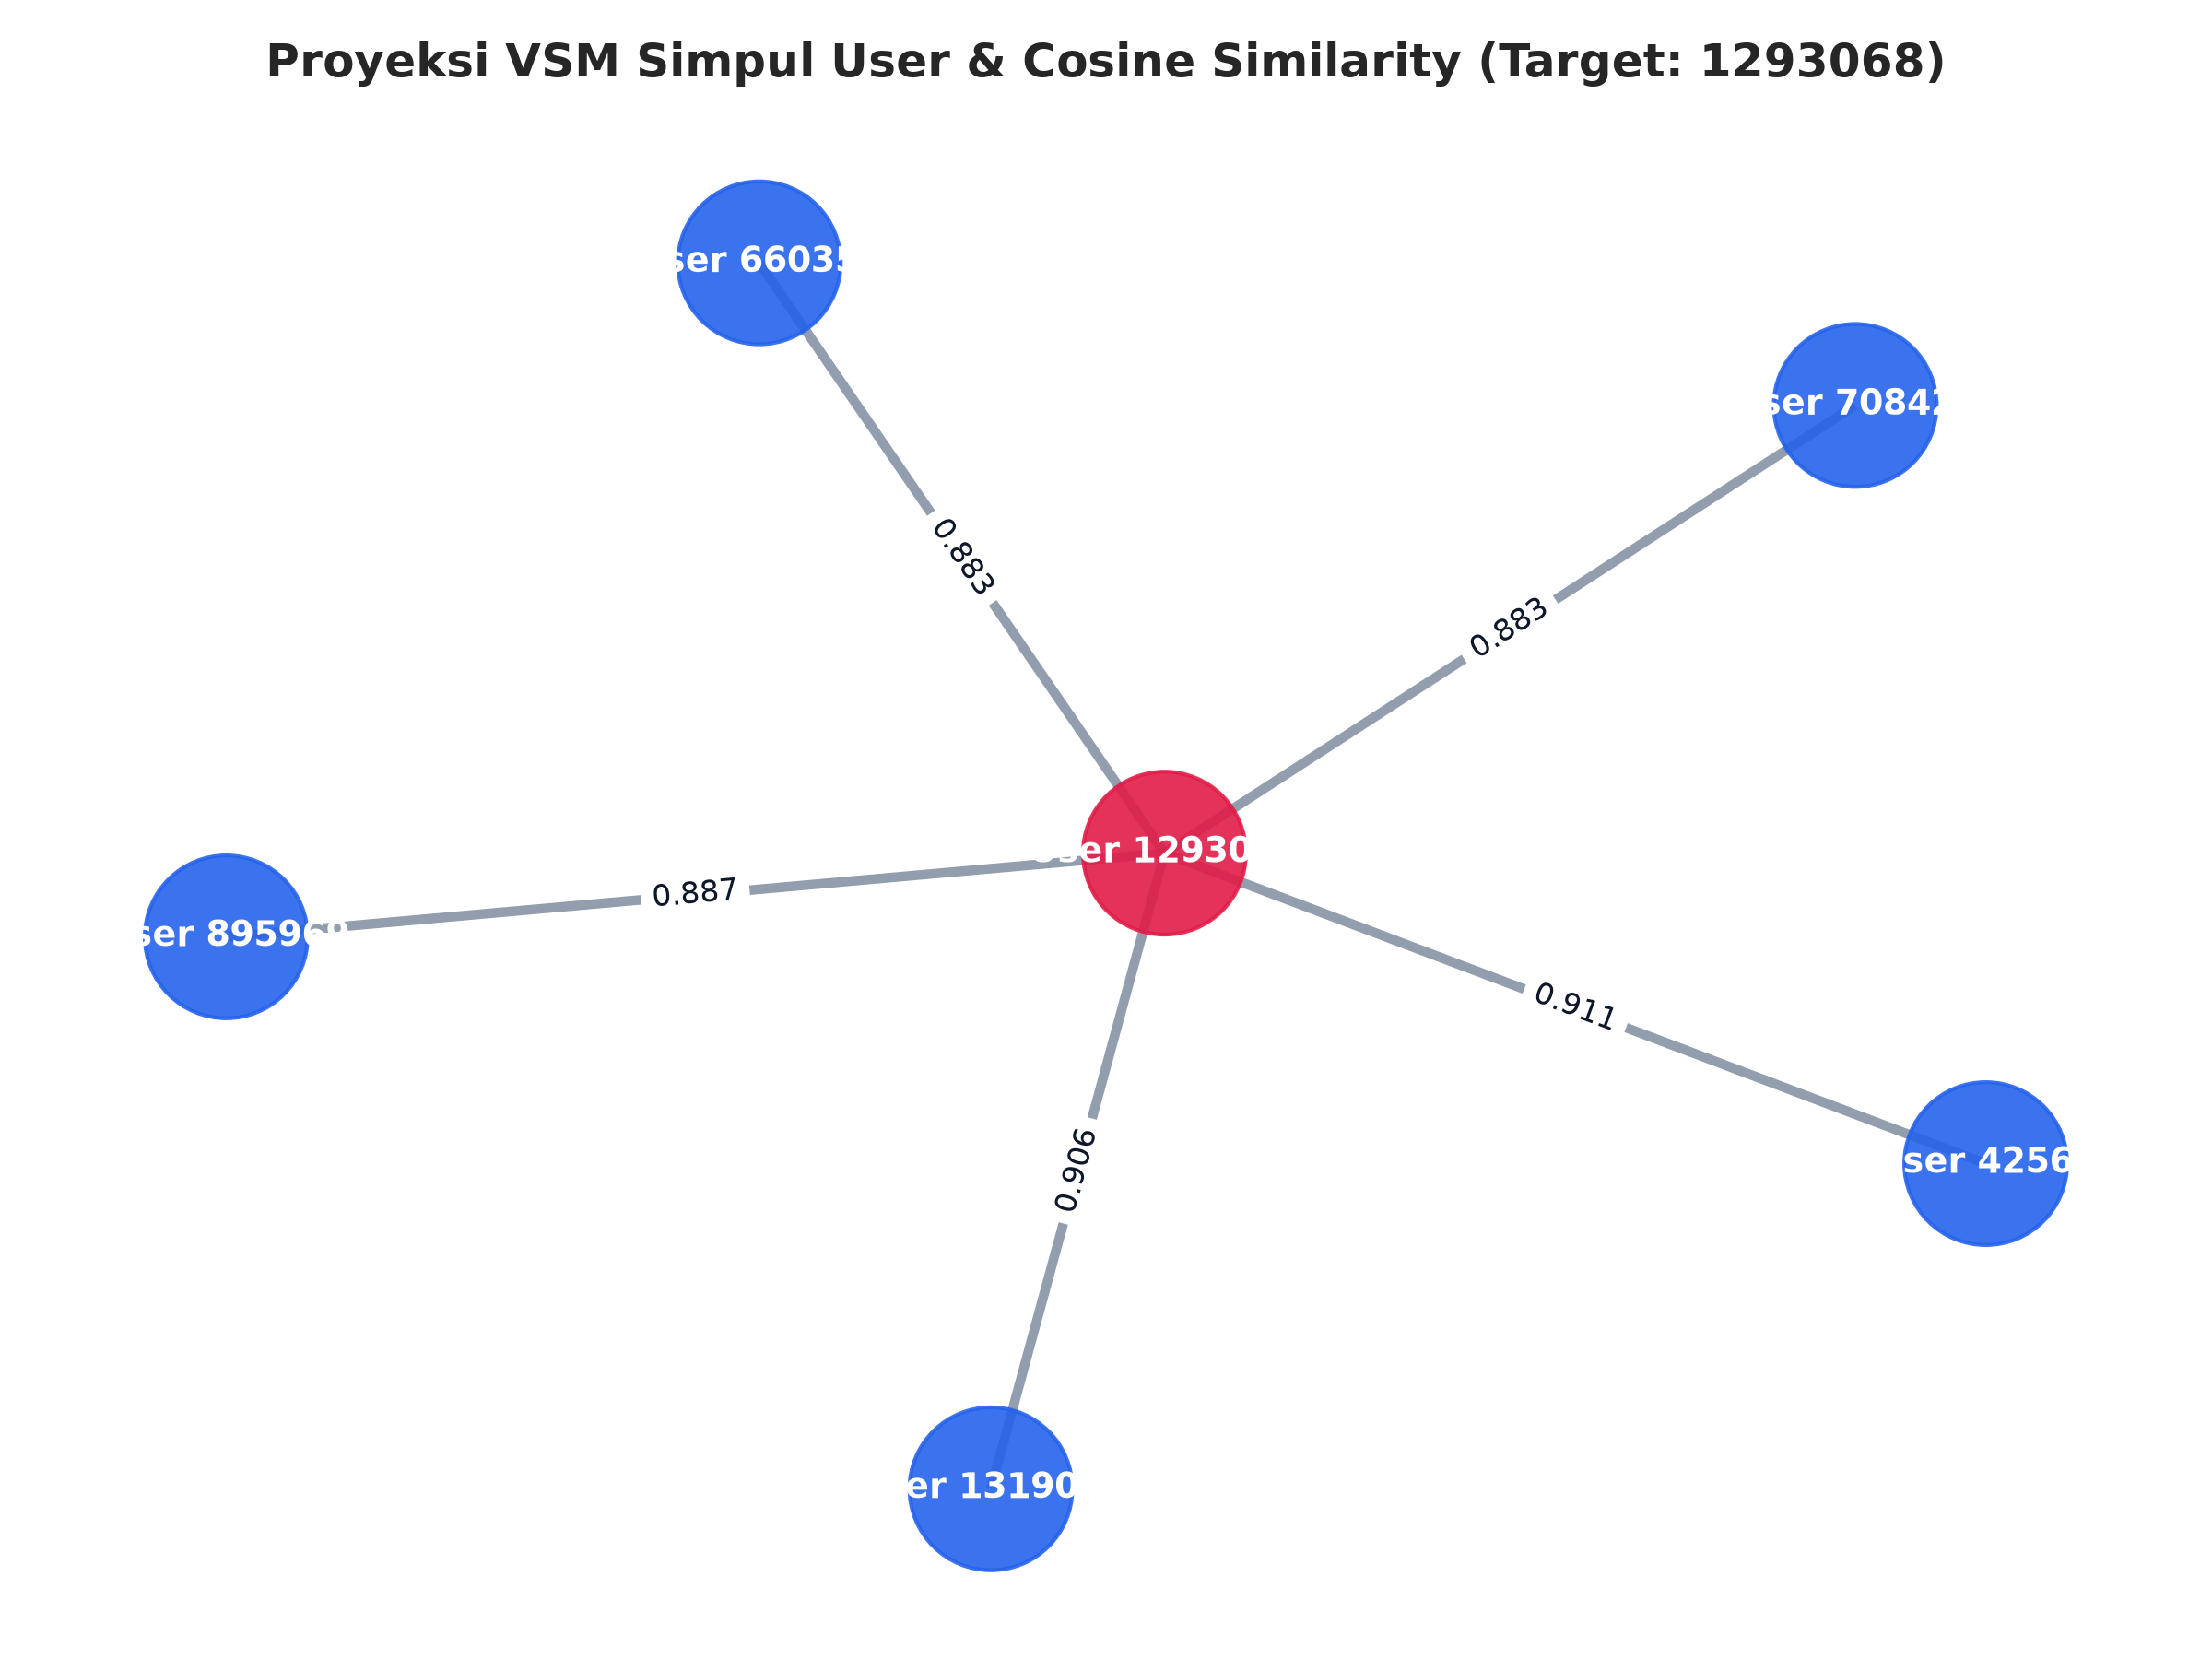

In [11]:
# Menampilkan visualisasi plot NetworkX VSM User Projection
from IPython.display import Image, display
display(Image(filename="plots/vsm_user_projection.png", width=650))

#### **2.1.5 Vector Space Modelling (VSM) Simpul Item**

Pada representasi VSM Simpul Item, setiap **Item** dimodelkan sebagai vektor dalam ruang berdimensi pengguna (User) yang berinteraksi dengannya.
- **Baris:** Item ($item_j \in I$)
- **Kolom:** User ($v_i \in U$)
- **Nilai Elemen ($M_{i, u}$):** Bobot interaksi ($M_{Item} = M_{User}^T$).

In [12]:
# Membangun Matriks VSM Item-User (Transpose dari VSM User)
mat_item = mat_user.T.tocsr()

print("=== Karakteristik VSM Simpul Item ===")
print(f"Dimensi Matriks (Shape) : ({n_items:,} Item, {n_users:,} User)")
print(f"Jumlah Fitur Dimensi    : {n_users:,} dimensi User")
print(f"Total Sel Matriks       : {total_elements:,}")
print(f"Elemen Non-Zero (nnz)   : {mat_item.nnz:,}")
print(f"Sparsity                : {sparsity_user:.2f}%")
print(f"Rata-rata User per Item : {mat_item.nnz / n_items:.2f} user")

=== Karakteristik VSM Simpul Item ===
Dimensi Matriks (Shape) : (9,137 Item, 374 User)
Jumlah Fitur Dimensi    : 374 dimensi User
Total Sel Matriks       : 3,417,238
Elemen Non-Zero (nnz)   : 14,568
Sparsity                : 99.57%
Rata-rata User per Item : 1.59 user


**Visualisasi Plot NetworkX Proyeksi VSM Simpul Item:**
Menampilkan graf proyeksi item (Item Co-occurrence Graph) di mana keterhubungan antar-item terbentuk dari pola *co-viewing* oleh pengunjung yang sama.

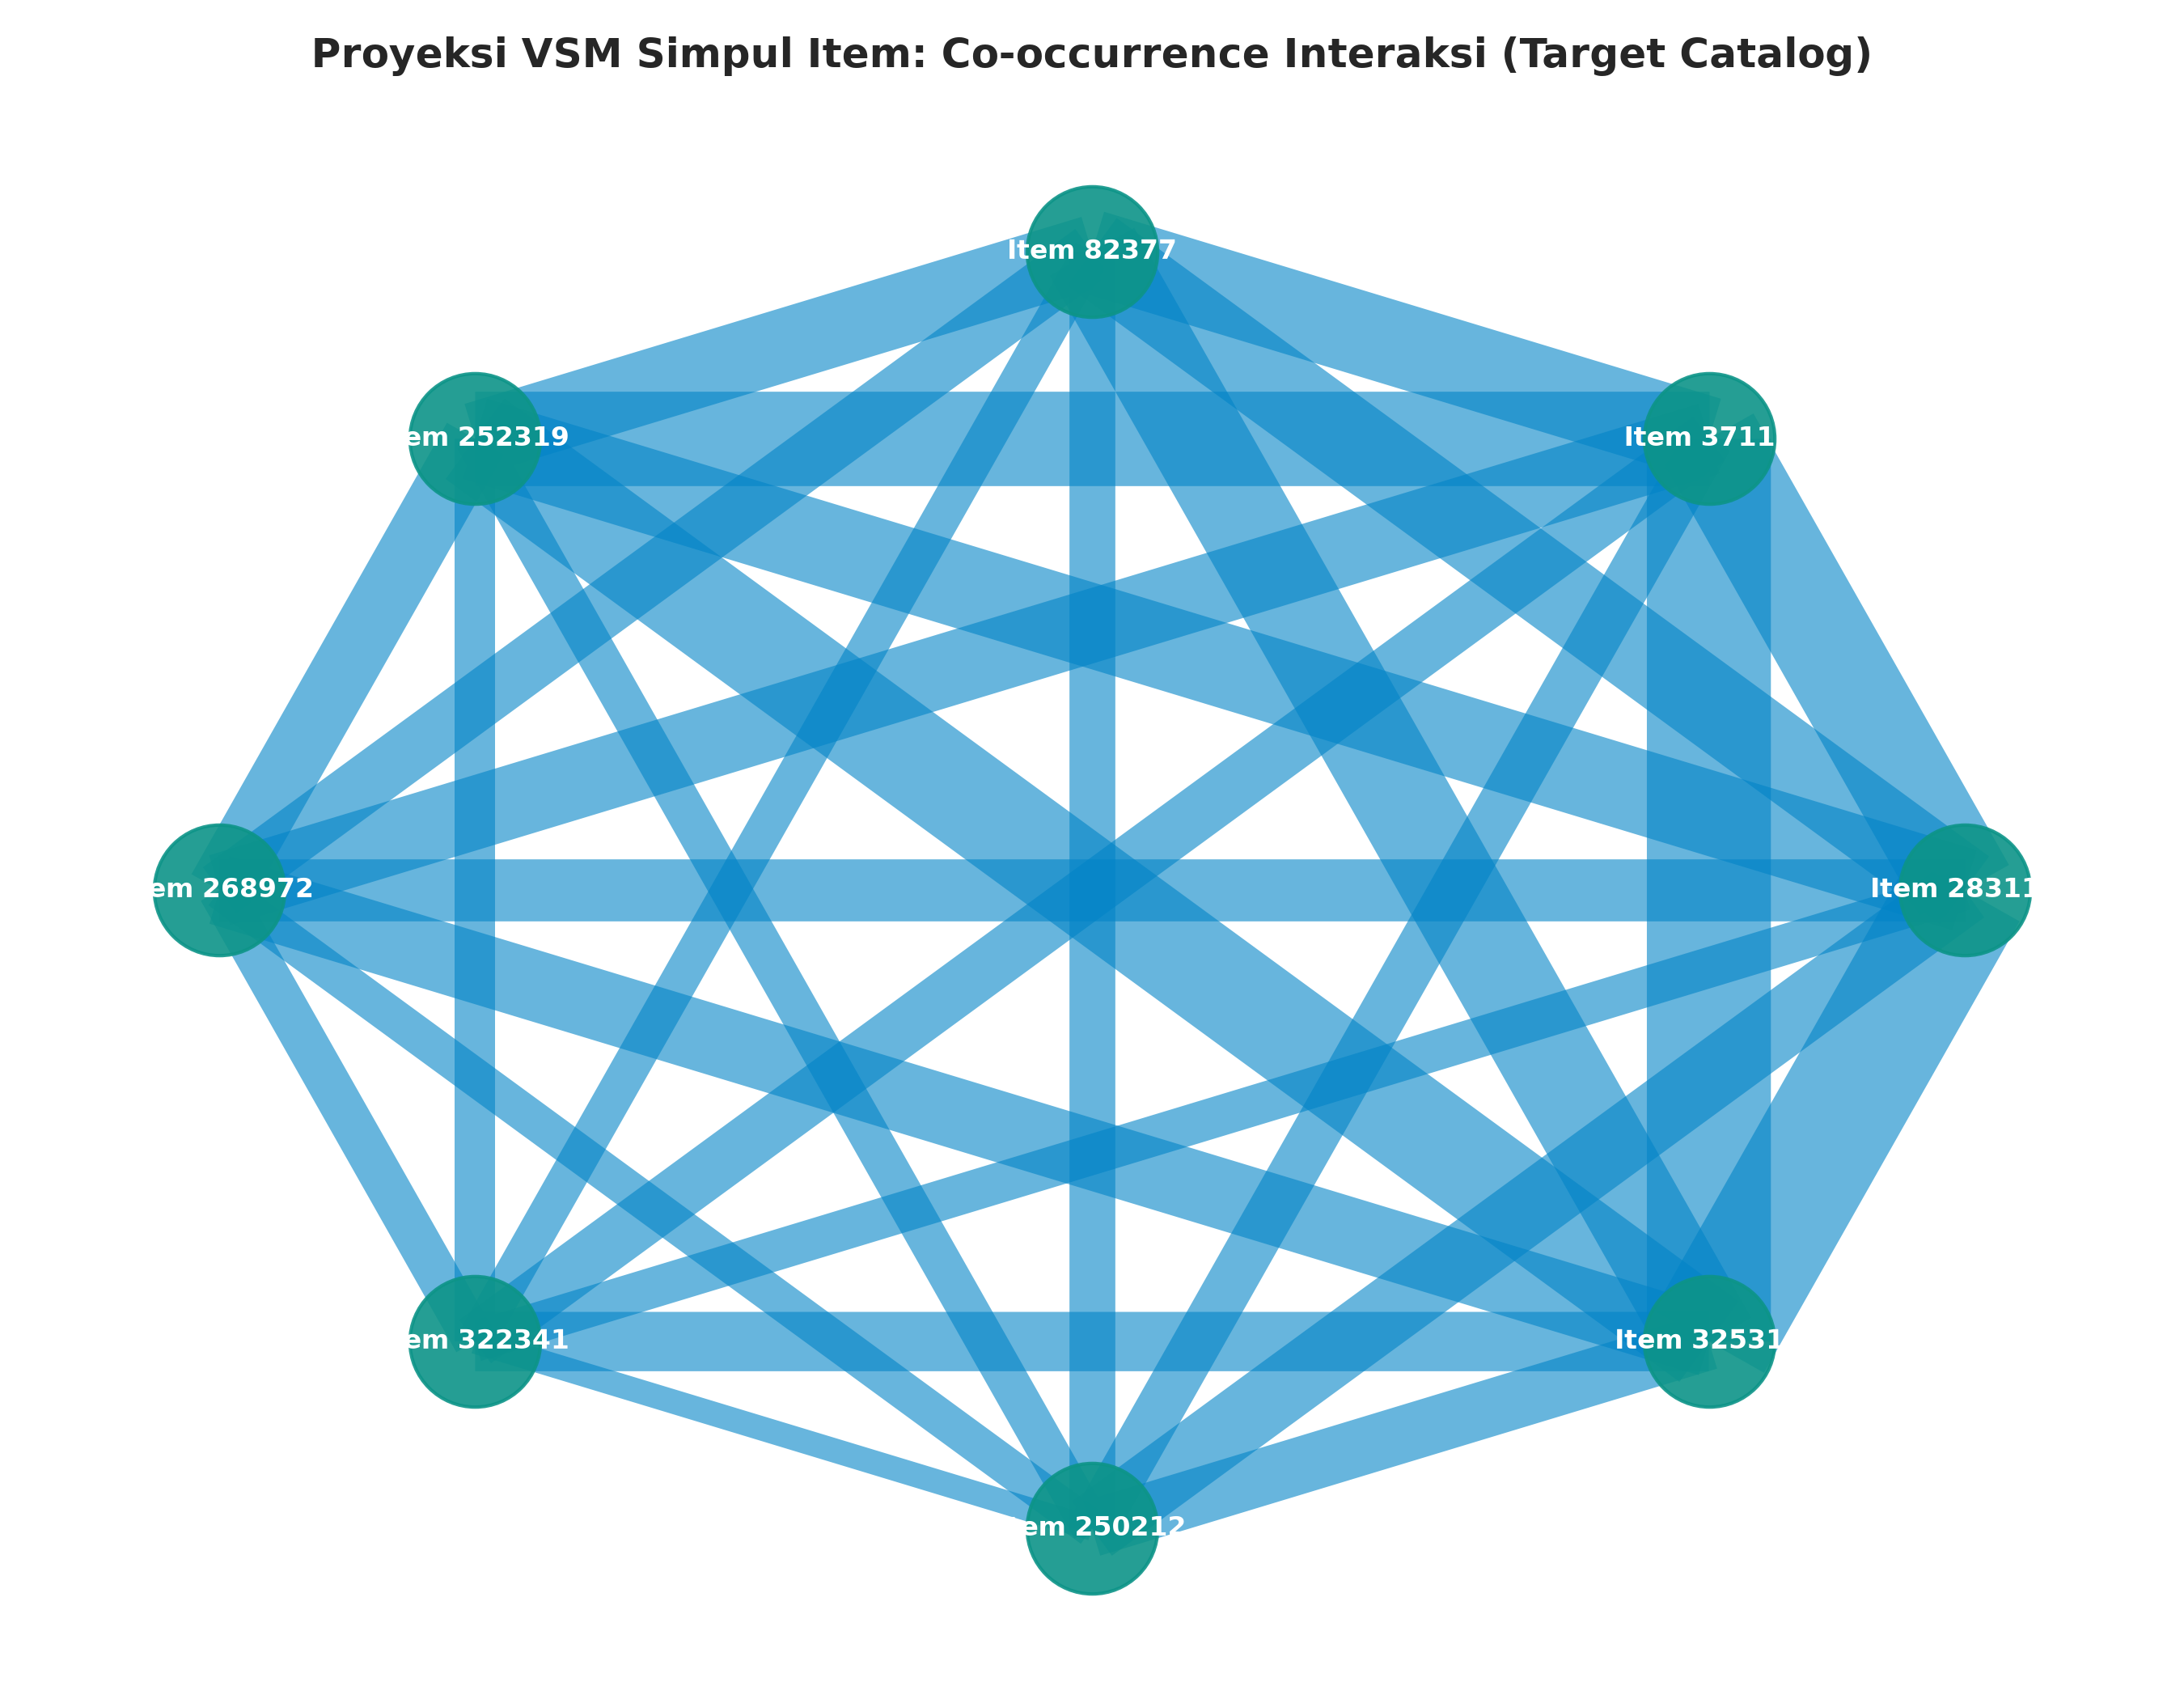

In [13]:
# Menampilkan visualisasi plot NetworkX VSM Item Projection
display(Image(filename="plots/vsm_item_projection.png", width=650))

#### **2.1.6 Evaluasi Komparatif Proyeksi User vs Item: Mana yang Lebih Efektif dan Efisien?**

Berdasarkan eksplorasi VSM pada Sub-bab 2.1.4 dan 2.1.5, perbandingan dilakukan pada aspek komputasi, karakteristik struktur graf, dan relevansi tujuan analisis:

| Parameter Evaluasi | Proyeksi Simpul User ($G_U$) | Proyeksi Simpul Item ($G_I$) |
| :--- | :--- | :--- |
| **Dimensi Objek ($N$)** | $374$ Simpul Pengunjung | $9.137$ Simpul Produk |
| **Dimensi Fitur ($D$)** | $9.137$ Item | $374$ Pengunjung |
| **Ukuran Matriks Similarity** | $374 \times 374$ ($139.876$ sel) | $9.137 \times 9.137$ ($83.484.869$ sel) |
| **Kompleksitas Komputasi** | $\mathcal{O}(\|U\|^2 \cdot \|I\|) \approx 1,28 \times 10^9$ FLOPs | $\mathcal{O}(\|I\|^2 \cdot \|U\|) \approx 3,12 \times 10^{10}$ FLOPs |
| **Kebutuhan Memori RAM** | Sangat Ringan (< 2 MB) | Sangat Berat (~650 MB untuk dense float64) |
| **Kerapatan Informasi (Density)** | Jauh lebih padat, komunitas pengguna jelas | Sangat renggang (*extremely sparse*), banyak *isolated nodes* |
| **Relevansi Tugas Analytics** | **Sangat Sesuai** untuk User-based KNN | Kurang efisien untuk personalisasi pengguna tunggal |

**Uraian Kesimpulan:**
1. **Efisiensi:** **Proyeksi Simpul User jauh lebih efisien** dengan komputasi **~24,4 kali lebih cepat** dan alokasi memori yang jauh lebih kecil dibandingkan proyeksi simpul Item.
2. **Efektivitas:** **Proyeksi Simpul User lebih efektif** untuk skenario sistem rekomendasi ini karena target tugas analitik (Soal 2.2) adalah merekomendasikan item baru kepada seorang user terpilih melalui *User-based Collaborative Filtering*. Graf pengguna yang terproyeksi secara langsung memodelkan relasi *neighborhood* dan kedekatan preferensi antar-pengunjung.

#### **2.1.7 Perhitungan Similarity pada Graf Terproyeksi dan Penulisan Kembali ke Neo4J**

Perhitungan kemiripan (Cosine Similarity) dilakukan antara target user **Visitor `1293068`** terhadap seluruh pengunjung lain dalam graf terproyeksi menggunakan Python:
$$\text{Cosine Similarity}(u, v) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|}$$

In [14]:
from sklearn.metrics.pairwise import cosine_similarity

# target_user sudah ditetapkan pada tahap pemilihan acak di atas
target_idx = user_map[target_user]
target_vec = mat_user[target_idx]

# Hitung similarity target user ke seluruh user
sims = cosine_similarity(target_vec, mat_user).flatten()
sorted_indices = np.argsort(sims)[::-1]

# Ambil 5 record dengan similarity tertinggi (selain target_user itu sendiri)
top5_indices = [idx for idx in sorted_indices if idx != target_idx][:5]

print(f"Top 5 Rekor Similarity Tertinggi untuk Record Acuan (Visitor: {target_user}):")
top5_records = []
for rank, idx in enumerate(top5_indices, 1):
    u_id = users[idx]
    score = float(sims[idx])
    top5_records.append({"source": target_user, "target": u_id, "score": score})
    print(f" {rank}. Visitor {u_id:<10} | Cosine Similarity = {score:.4f}")

Top 5 Rekor Similarity Tertinggi untuk Record Acuan (Visitor: 1293068):
 1. Visitor 42561      | Cosine Similarity = 0.9107
 2. Visitor 1319005    | Cosine Similarity = 0.9064
 3. Visitor 895969     | Cosine Similarity = 0.8867
 4. Visitor 708420     | Cosine Similarity = 0.8825
 5. Visitor 660351     | Cosine Similarity = 0.8825


##### **(a) Kueri CYPHER untuk Mendapatkan 5 Records dengan Similarity Tertinggi:**
```cypher
MATCH (u1:Visitor {visitorId: 1293068})-[r:SIMILAR]->(u2:Visitor)
RETURN u1.visitorId AS sourceUser, u2.visitorId AS similarUser, r.score AS similarityScore
ORDER BY r.score DESC
LIMIT 5;
```

##### **(b) Menuliskan Kembali Nilai Similarity ke Graf Neo4J dan Menampilkan Hasil Kuerinya:**

In [15]:
# Penulisan kembali nilai similarity ke Neo4j
write_query = '''
UNWIND $batch AS rec
MATCH (u1:Visitor {visitorId: rec.source})
MATCH (u2:Visitor {visitorId: rec.target})
MERGE (u1)-[r:SIMILAR]->(u2)
SET   r.score = rec.score
RETURN count(r) AS updatedCount
'''

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        session.execute_write(lambda tx: tx.run(write_query, batch=top5_records))
        
        # Eksekusi kueri verifikasi (Soal 2.1.7b)
        cypher_verify = '''
        MATCH (u1:Visitor {visitorId: $target})-[r:SIMILAR]->(u2:Visitor)
        RETURN u1.visitorId AS sourceUser, u2.visitorId AS similarUser, r.score AS similarityScore
        ORDER BY r.score DESC
        LIMIT 5
        '''
        records = session.run(cypher_verify, target=target_user)
        print("Hasil Kueri CYPHER dari Graf Neo4J (Verifikasi Relasi SIMILAR):")
        for rec in records:
            print(f"(:Visitor {{visitorId: {rec['sourceUser']}}})-[:SIMILAR {{score: {rec['similarityScore']:.4f}}}]->(:Visitor {{visitorId: {rec['similarUser']}}})")

Hasil Kueri CYPHER dari Graf Neo4J (Verifikasi Relasi SIMILAR):


(:Visitor {visitorId: 1293068})-[:SIMILAR {score: 0.9107}]->(:Visitor {visitorId: 42561})
(:Visitor {visitorId: 1293068})-[:SIMILAR {score: 0.9064}]->(:Visitor {visitorId: 1319005})
(:Visitor {visitorId: 1293068})-[:SIMILAR {score: 0.8867}]->(:Visitor {visitorId: 895969})
(:Visitor {visitorId: 1293068})-[:SIMILAR {score: 0.8825}]->(:Visitor {visitorId: 708420})
(:Visitor {visitorId: 1293068})-[:SIMILAR {score: 0.8825}]->(:Visitor {visitorId: 660351})


#### **2.1.8 Perbandingan Kondisi Graf SEBELUM dan SESUDAH Perhitungan Similarity**

##### **1. Kondisi SEBELUM Perhitungan Similarity**
- Struktur graf berjenis **Bipartite Graph (Two-mode network)**.
- Hanya terdapat simpul berlabel `:Visitor` dan `:Item`.
- Relasi yang ada hanyalah interaksi dari pengunjung ke produk (`[:VIEWED]`, `[:ADDED_TO_CART]`, `[:BOUGHT]`). Tidak ada relasi langsung antar-simpul berlabel sama.
- **Kueri CYPHER Kondisi Sebelum:**
  ```cypher
  // Memeriksa relasi bipartite dan memastikan ketiadaan relasi SIMILAR
  MATCH (v:Visitor {visitorId: 1293068})-[r]->(i:Item)
  RETURN type(r) AS relType, count(r) AS interactionCount;
  ```

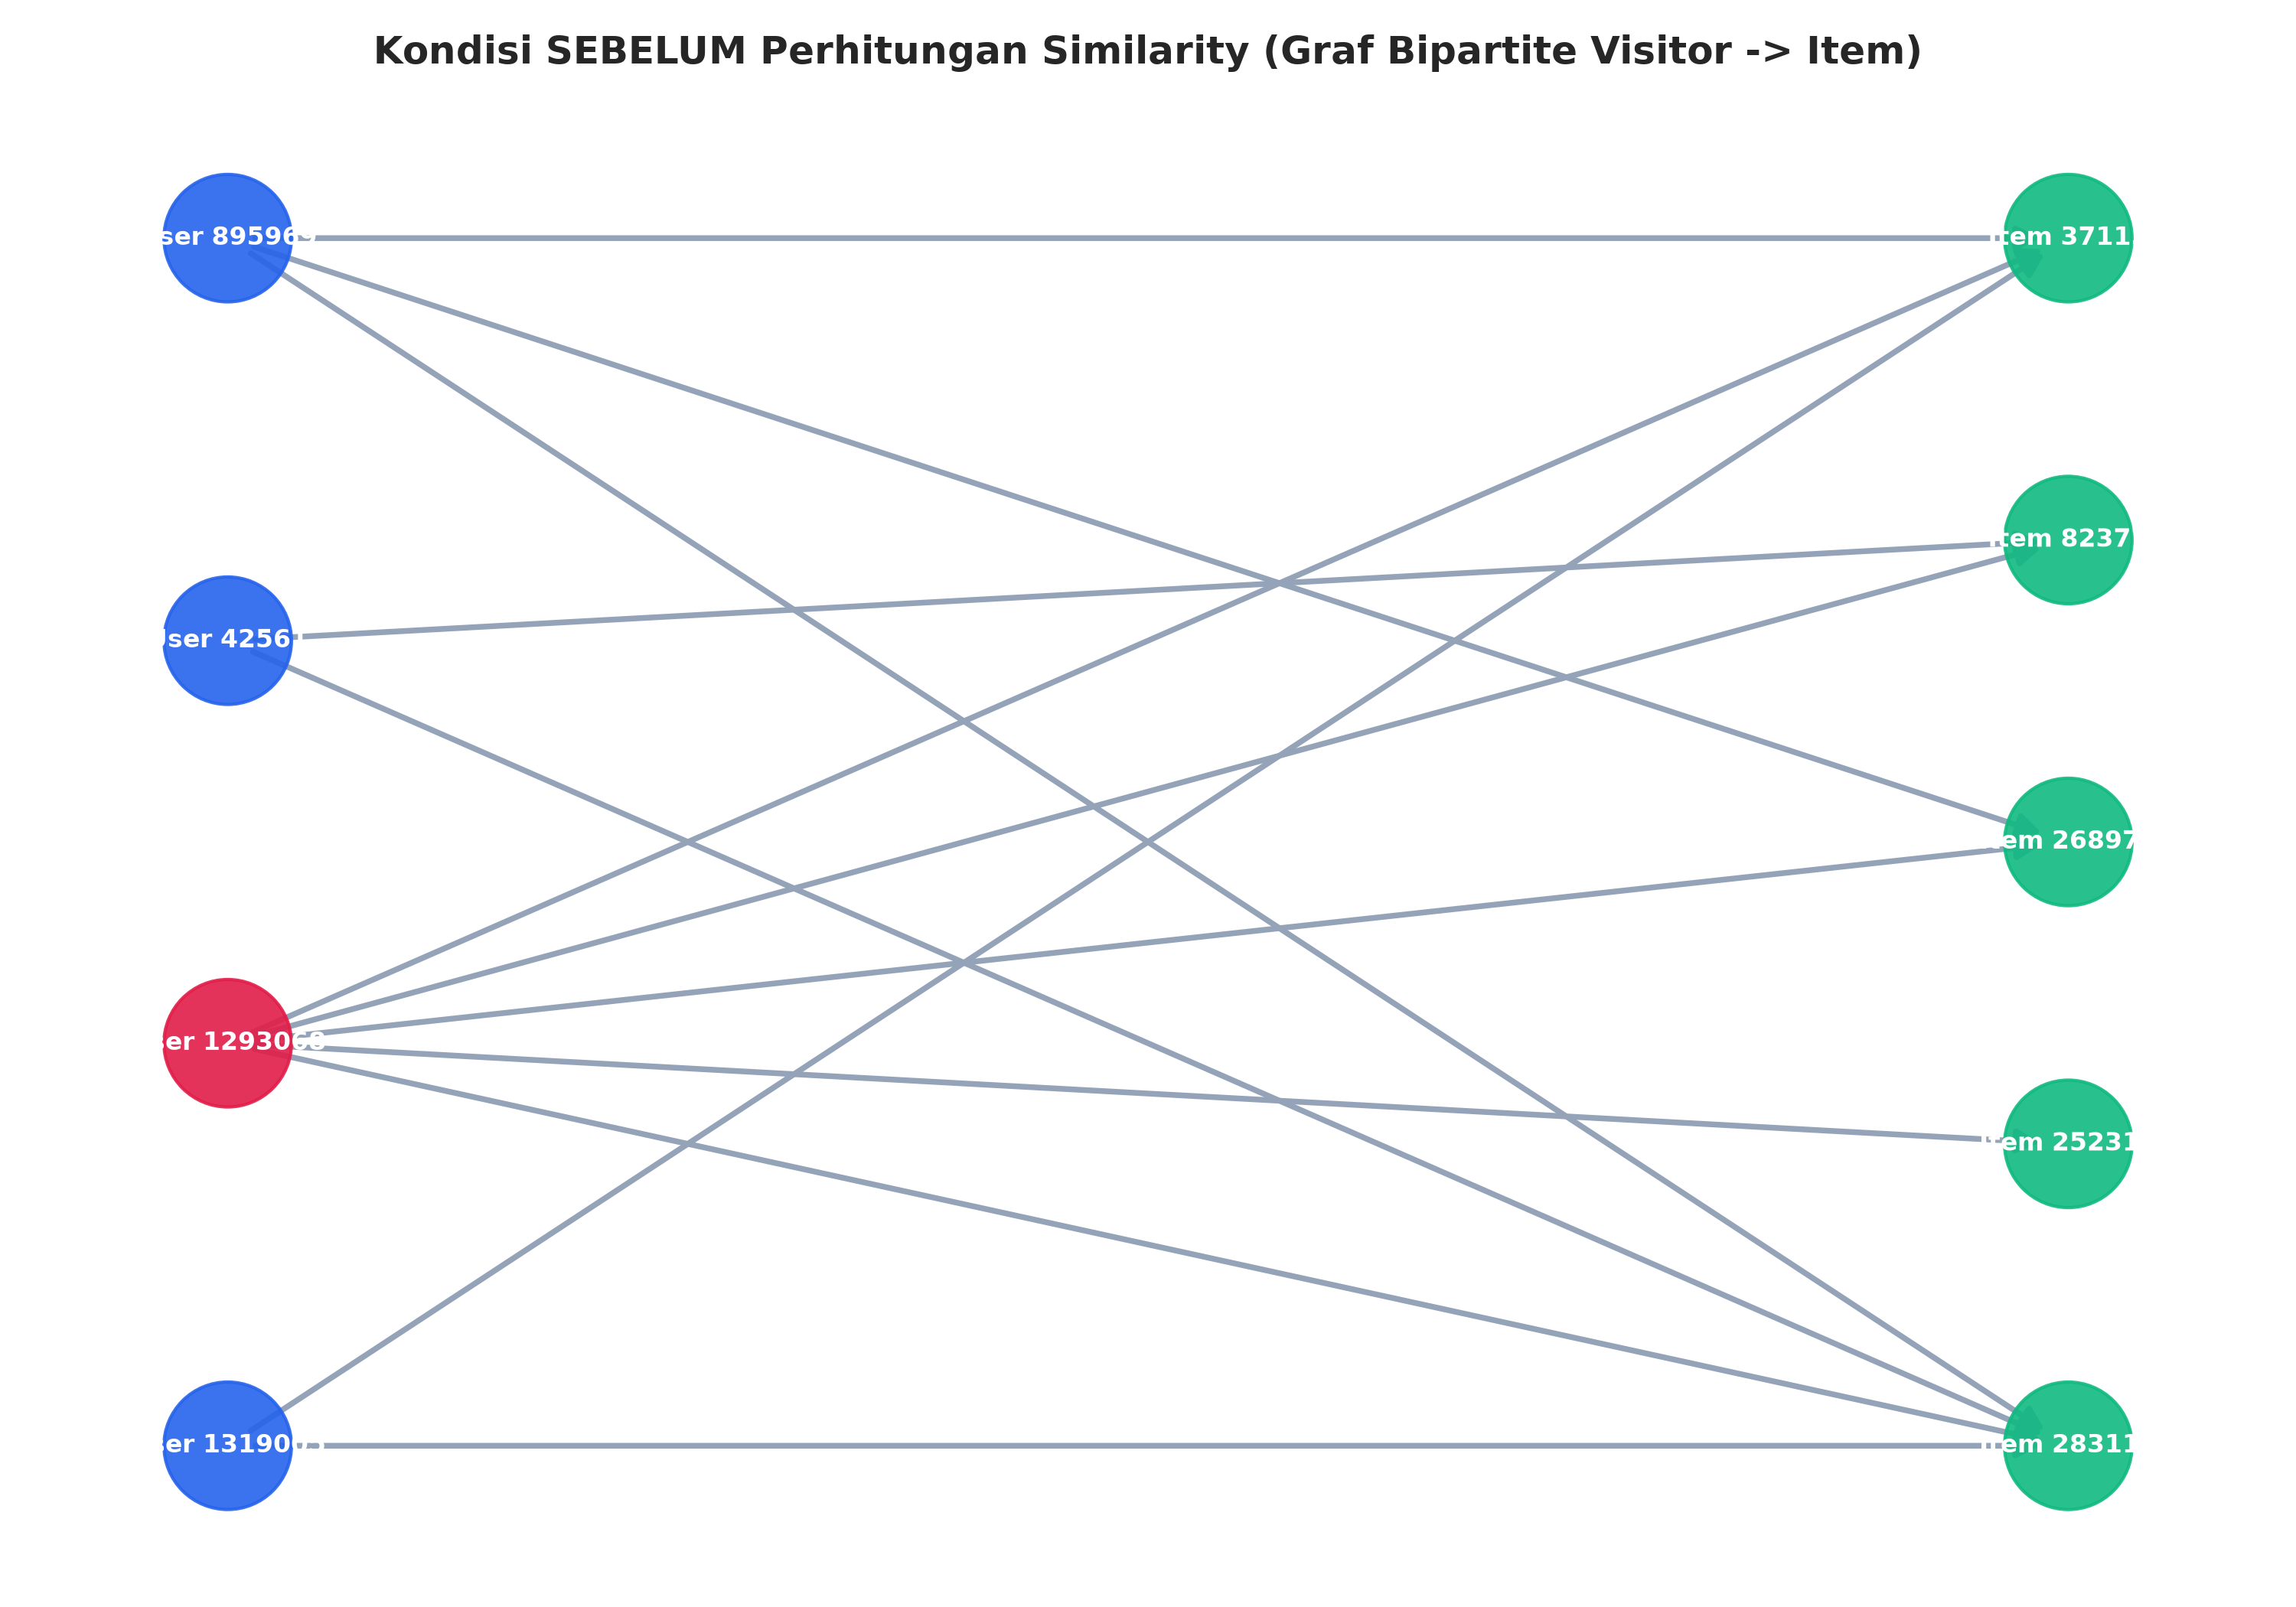

In [16]:
# Menampilkan visualisasi kondisi SEBELUM perhitungan similarity
display(Image(filename="plots/graph_before_similarity.png", width=700))

##### **2. Kondisi SESUDAH Perhitungan Similarity**
- Struktur graf bertransformasi menjadi **Homogeneous / Monopartite Network** antar-pengunjung yang diperkaya (*enriched graph*).
- Terdapat relasi baru `[:SIMILAR {score: ...}]` yang menghubungkan langsung simpul `:Visitor` dengan tetangga terdekatnya berdasarkan kedekatan vektor preferensi.
- **Kueri CYPHER Kondisi Sesudah:**
  ```cypher
  // Membaca relasi SIMILAR yang telah tersimpan antar-Visitor
  MATCH (v1:Visitor {visitorId: 1293068})-[r:SIMILAR]->(v2:Visitor)
  RETURN v1.visitorId AS focalUser, v2.visitorId AS neighborUser, r.score AS similarityScore
  ORDER BY r.score DESC;
  ```

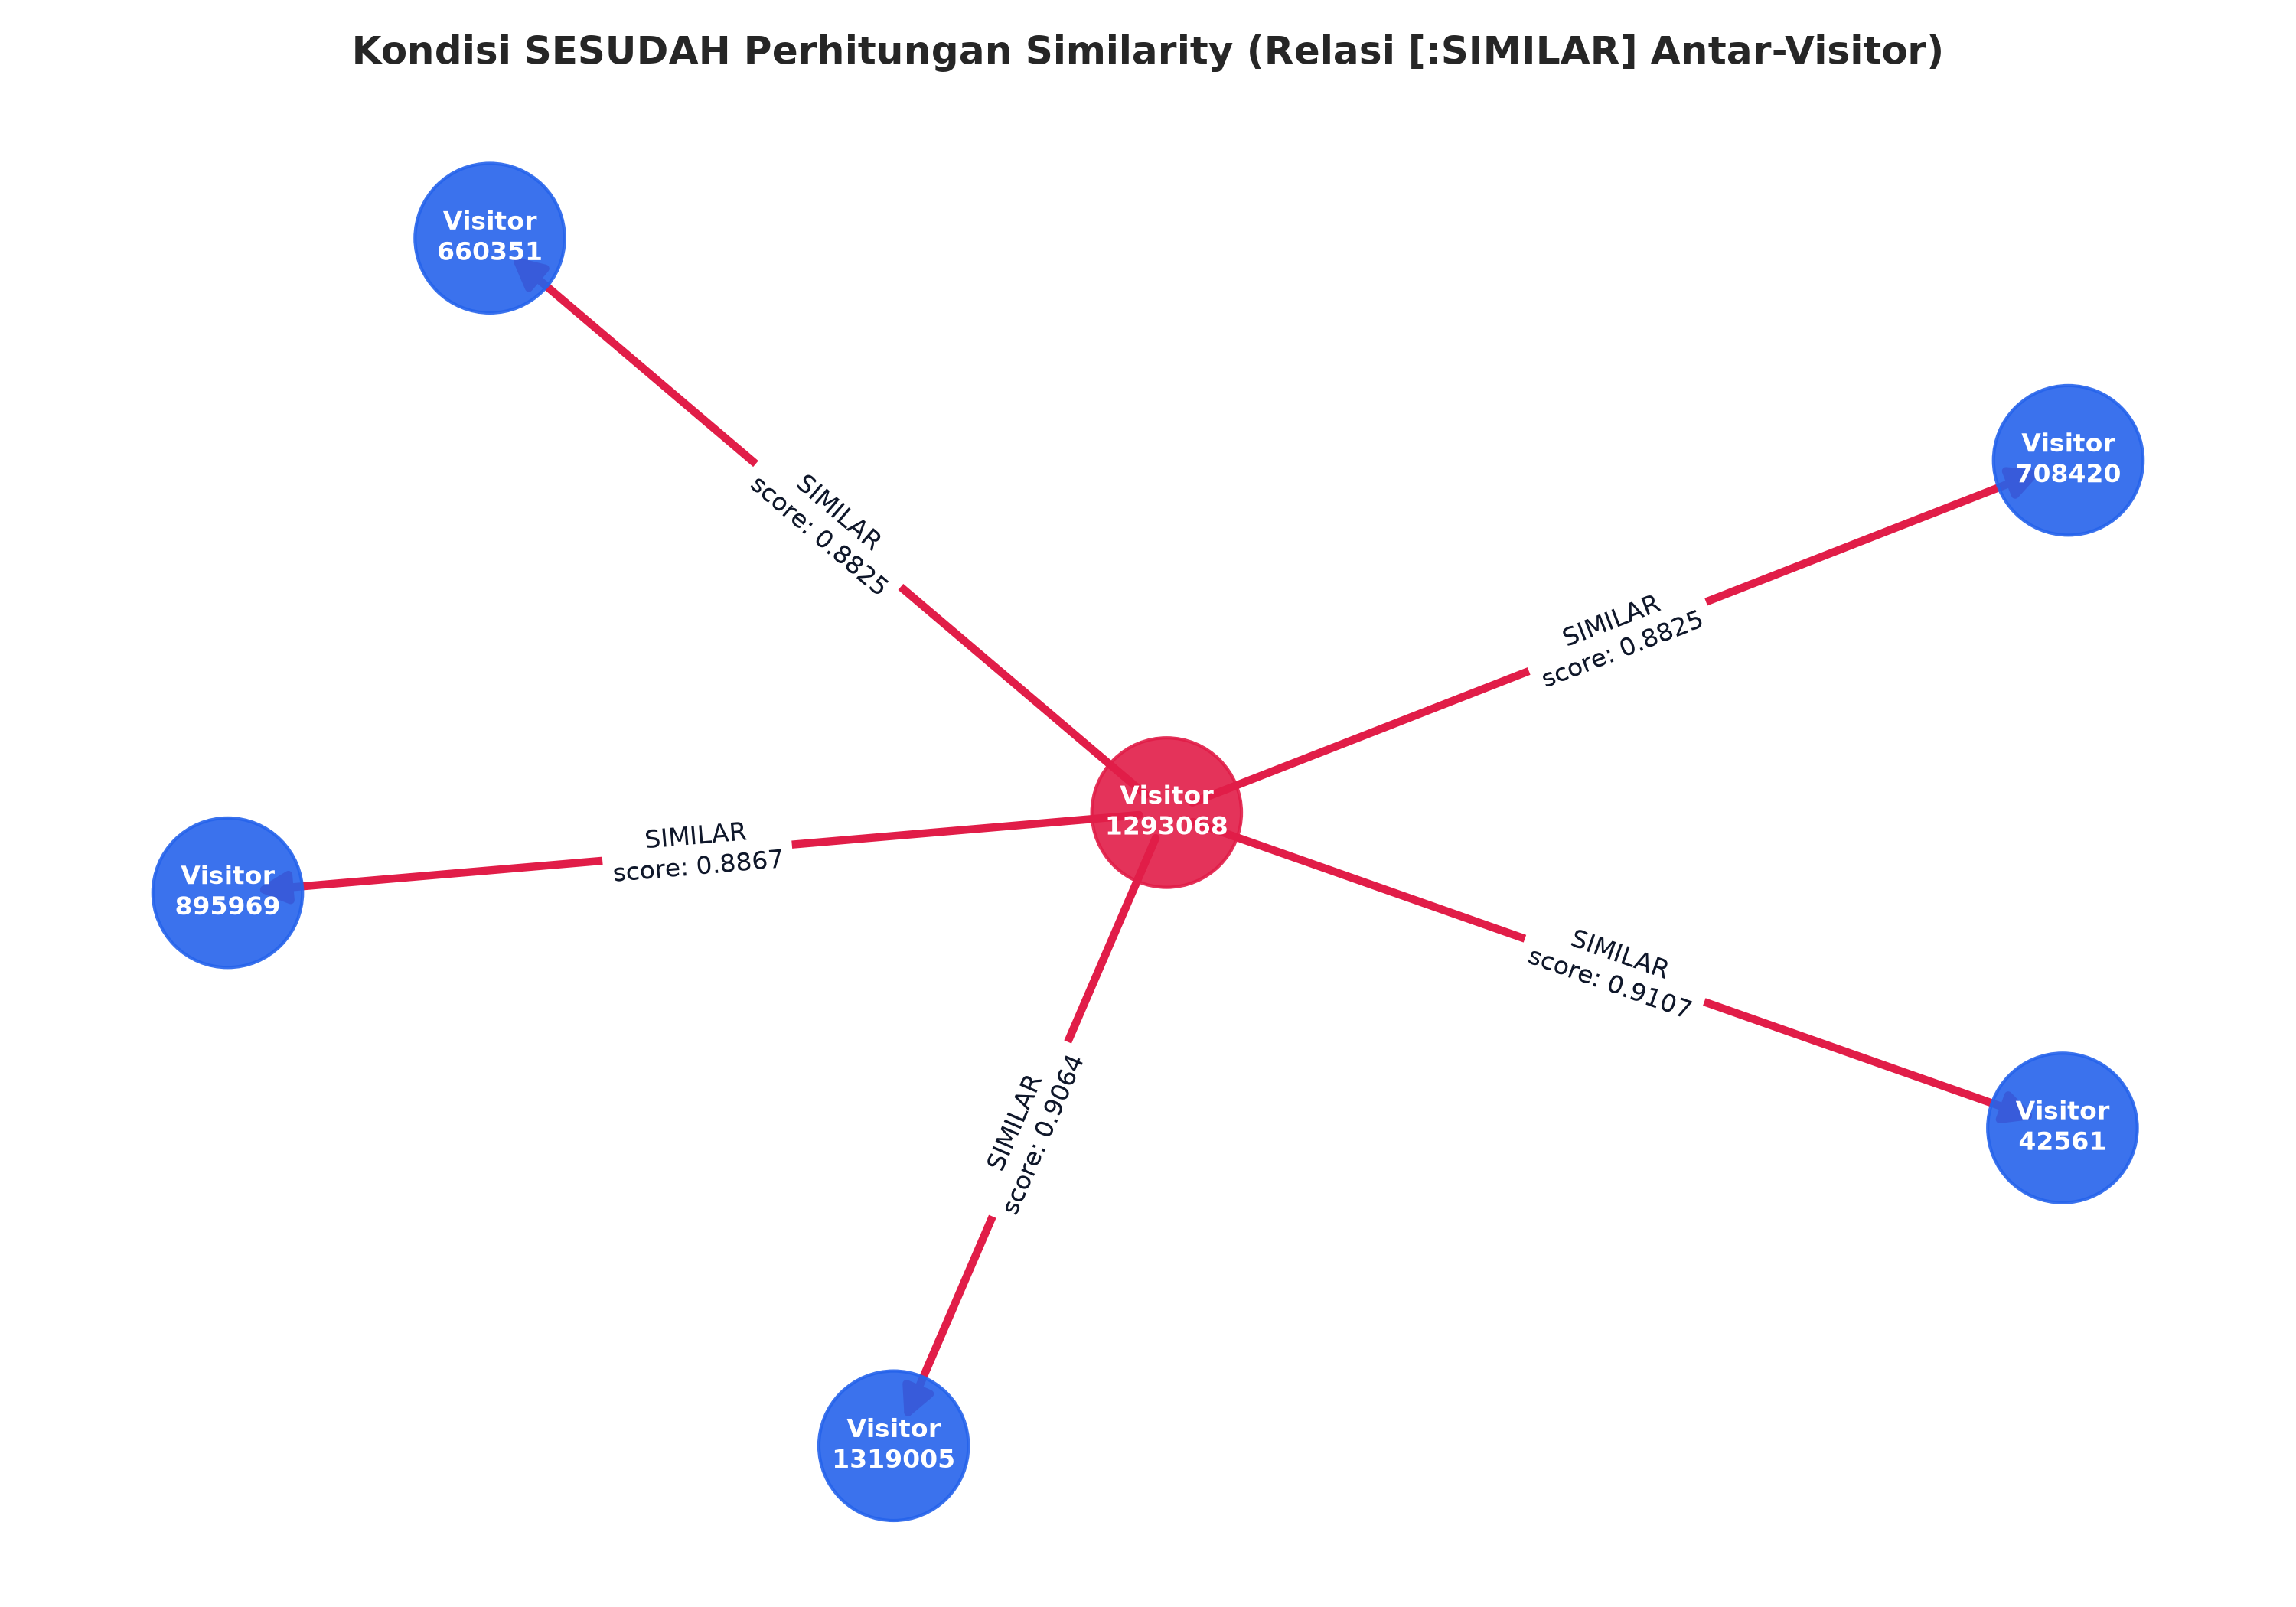

In [17]:
# Menampilkan visualisasi kondisi SESUDAH perhitungan similarity
display(Image(filename="plots/graph_after_similarity.png", width=700))

---
### **2.2 Analytics**

#### **2.2.1 Rekomendasi Collaborative Filtering KNN ($k=5$)**

1. **User target dan proses acaknya**
   - Pemilihan user sudah dilakukan di bagian awal memakai `np.random.seed(732)` terhadap daftar kandidat yang diurutkan, jadi hasilnya tetap sama setiap kali notebook dijalankan ulang.
   - Kandidatnya dibatasi pada user yang aktif di P1 maupun P2 dengan minimal 15 interaksi di P1, dan yang terpilih adalah Visitor `1293068`.
   - User ini punya 19 interaksi di P1 (8 item unik) dan 12 interaksi di P2 (7 item unik).

2. **Cara kerja rekomendasinya**
   - Cari $k=5$ tetangga terdekat dari user target berdasarkan cosine similarity.
   - Kumpulkan item-item yang pernah disentuh tetangga tapi belum pernah disentuh user target.
   - Hitung skor prediksi dengan menjumlahkan bobot interaksi tetangga yang dikalikan nilai similarity-nya:
     $$\hat{r}_{u, i} = \sum_{v \in \mathcal{N}_k(u)} \text{sim}(u, v) \cdot w_{v, i}$$
     dengan $w_{v, i}$ bernilai 1.0 (view), 2.0 (addtocart), dan 3.0 (transaction).

In [18]:
# Menjalankan Algoritma Rekomendasi KNN (k=5)
user_p1_items = set(sub_df[sub_df["visitorid"] == target_user]["itemid"])

candidate_scores = {}
event_weights = {"view": 1.0, "addtocart": 2.0, "transaction": 3.0}

for rec in top5_records:
    n_user = rec["target"]
    n_sim = rec["score"]
    n_events = sub_df[sub_df["visitorid"] == n_user]
    
    for _, row in n_events.iterrows():
        it = int(row["itemid"])
        if it not in user_p1_items:
            w = event_weights.get(row["event"], 1.0)
            candidate_scores[it] = candidate_scores.get(it, 0.0) + (n_sim * w)

sorted_candidates = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)

print("=== 3 Item yang Diiklankan untuk k = 5 (Soal 2.2.1b) ===")
for rank, (it, score) in enumerate(sorted_candidates[:3], 1):
    print(f"Rank {rank}: Item ID {it:<10} | Skor Prediksi Preferensi: {score:.4f}")

=== 3 Item yang Diiklankan untuk k = 5 (Soal 2.2.1b) ===
Rank 1: Item ID 38965      | Skor Prediksi Preferensi: 3.5862
Rank 2: Item ID 241555     | Skor Prediksi Preferensi: 3.5709
Rank 3: Item ID 265571     | Skor Prediksi Preferensi: 2.6602


#### **2.2.2 Evaluasi Rekomendasi: Hit@5 dan NDCG@5**

Rekomendasi model dievaluasi secara offline terhadap data faktual interaksi pengunjung target pada **Fold Testing (P2)**.
- **Ground Truth P2 Visitor `1293068`:** Terdiri dari 7 item unik: `{9877, 37115, 96377, 98747, 239006, 241555, 283115}`.

In [19]:
# Membaca data Fold Testing (P2) untuk Visitor target
df_p2 = pd.read_csv("data/events_p2_test.csv")
p2_user = df_p2[df_p2["visitorid"] == target_user]
p2_ground_truth = set(p2_user["itemid"].unique())

print(f"Item faktual yang diakses Visitor {target_user} pada Fold Testing P2:")
for it in sorted(p2_ground_truth):
    print(f" - Item ID {it}")

# Evaluasi Top 5 Rekomendasi
top_5_items = [it for it, _ in sorted_candidates[:5]]
hits = [1 if it in p2_ground_truth else 0 for it in top_5_items]

print("\n=== Detail Evaluasi Rekomendasi Top-5 ===")
for rank, (it, hit) in enumerate(zip(top_5_items, hits), 1):
    status = "HIT (Sesuai dengan aktivitas P2!)" if hit == 1 else "Not in P2"
    print(f"Rank {rank}: Item {it:<10} | Indikator Hit: {hit} -> {status}")

# Perhitungan Hit@5
hit_at_5 = 1 if sum(hits) > 0 else 0

# Perhitungan DCG@5
dcg_5 = sum([h / np.log2(idx + 2) for idx, h in enumerate(hits)])

# Perhitungan IDCG@5 (Ideal DCG bila item hit menempati peringkat teratas)
idcg_5 = sum([1 / np.log2(idx + 2) for idx in range(min(len(p2_ground_truth), 5))])

# Perhitungan NDCG@5
ndcg_5 = dcg_5 / idcg_5 if idcg_5 > 0 else 0.0

print(f"\n================ HASIL AKHIR EVALUASI ================")
print(f"Hit@5  : {hit_at_5} ({sum(hits)} dari 5 item rekomendasi diakses user pada testing)")
print(f"DCG@5  : {dcg_5:.4f}")
print(f"IDCG@5 : {idcg_5:.4f}")
print(f"NDCG@5 : {ndcg_5:.4f}")
print(f"=======================================================")

Item faktual yang diakses Visitor 1293068 pada Fold Testing P2:
 - Item ID 9877
 - Item ID 37115
 - Item ID 96377
 - Item ID 98747
 - Item ID 239006
 - Item ID 241555
 - Item ID 283115

=== Detail Evaluasi Rekomendasi Top-5 ===
Rank 1: Item 38965      | Indikator Hit: 0 -> Not in P2
Rank 2: Item 241555     | Indikator Hit: 1 -> HIT (Sesuai dengan aktivitas P2!)
Rank 3: Item 265571     | Indikator Hit: 0 -> Not in P2
Rank 4: Item 239006     | Indikator Hit: 1 -> HIT (Sesuai dengan aktivitas P2!)
Rank 5: Item 381941     | Indikator Hit: 0 -> Not in P2

================ HASIL AKHIR EVALUASI ================
Hit@5  : 1 (2 dari 5 item rekomendasi diakses user pada testing)
DCG@5  : 1.0616
IDCG@5 : 2.9485
NDCG@5 : 0.3601


**Visualisasi Evaluasi Rekomendasi Top-5 Item:**
Menampilkan diagram batang peringkat item yang direkomendasikan beserta status keberhasilan *Hit* pada periode pengujian P2.

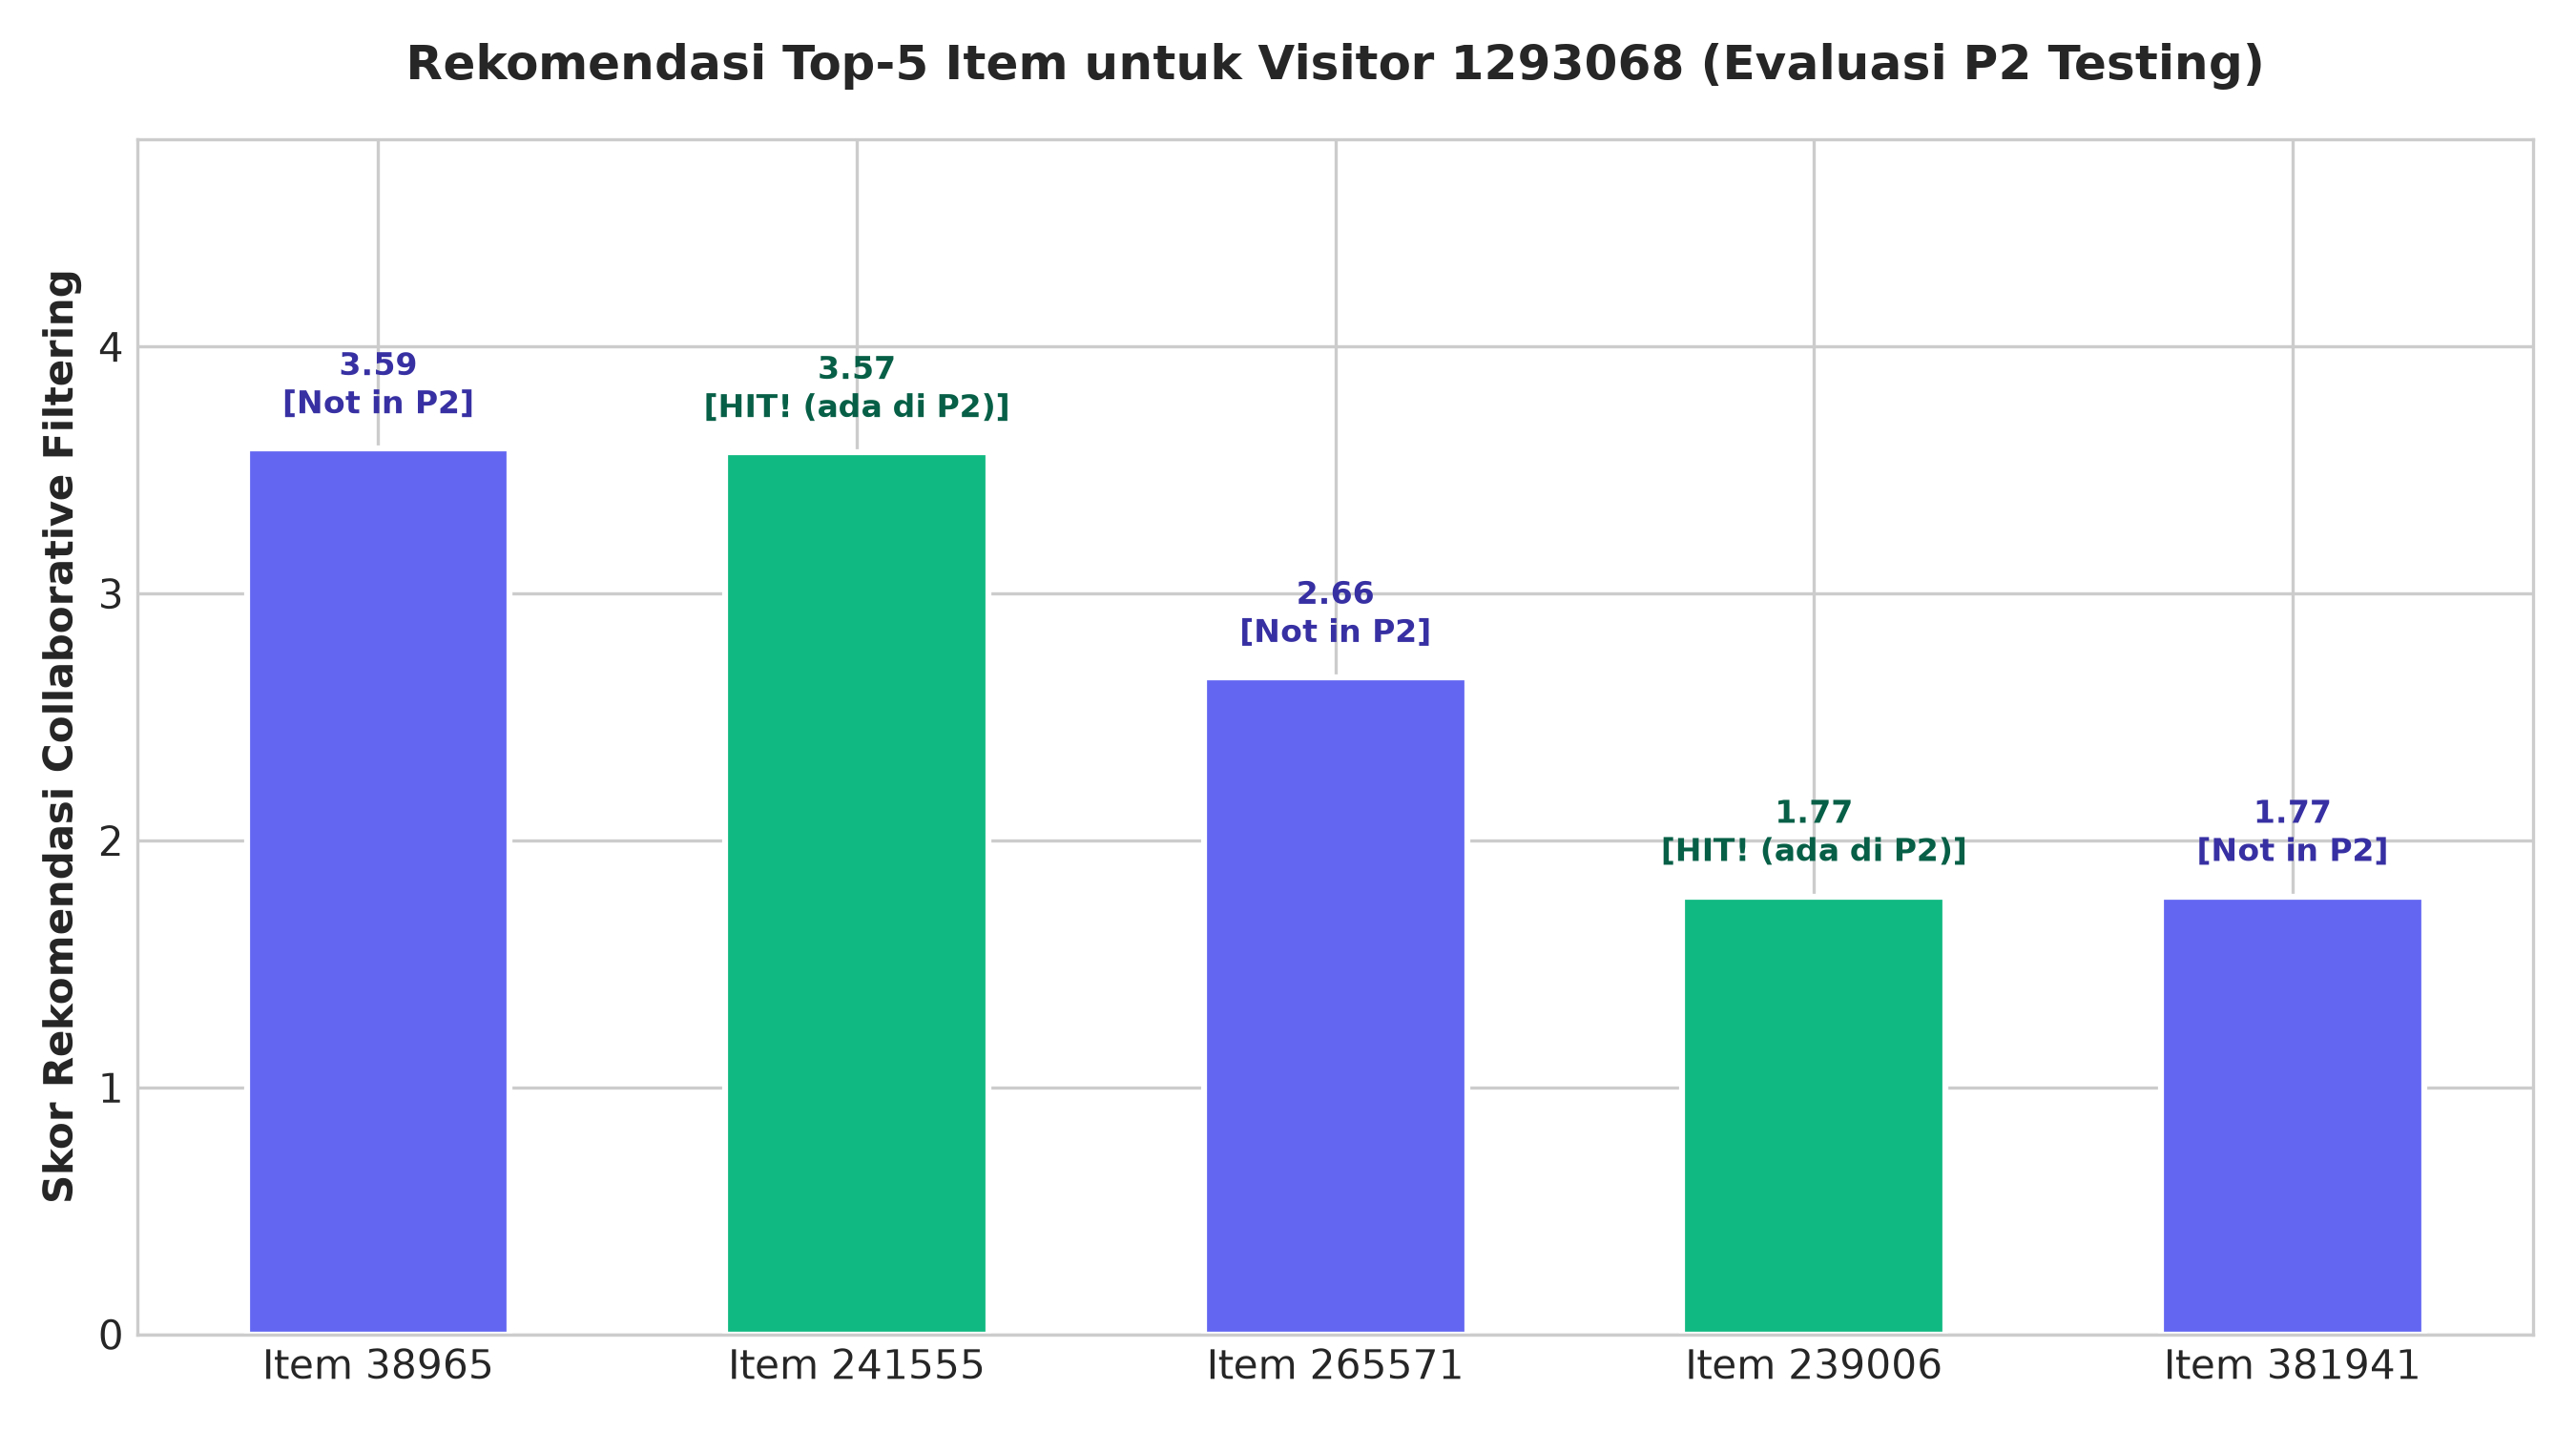

In [20]:
# Menampilkan visualisasi evaluasi rekomendasi KNN
display(Image(filename="plots/knn_recommendations.png", width=700))

**Bagaimana membaca hasilnya:**

1. **Hit@5 = 1.** Dari 5 item yang direkomendasikan, ada 2 yang benar-benar diakses user pada periode testing, yaitu Item `241555` di peringkat 2 dan Item `239006` di peringkat 4. Hit@5 sendiri sifatnya biner per user: bernilai 1 kalau minimal ada satu item relevan yang kena. Kalau yang ditanya proporsinya, 2 dari 5 item itu adalah Precision@5 = 0.4, metrik yang berbeda.
2. **NDCG@5 = 0.3601.** Metrik ini ikut memperhitungkan posisi, bukan cuma ada atau tidaknya hit. Karena satu item relevan kena di peringkat 2, kontribusinya cukup besar ($1/\log_2 3 = 0.6309$ dari total DCG 1.0616). Nilai 0.3601 berarti kualitas urutan rekomendasi mencapai sekitar 36% dari kondisi idealnya.
3. Untuk data implicit feedback dengan sparsity 99.57% dan tanpa model yang dilatih sama sekali, hasil segini masih wajar. Yang perlu dicatat, evaluasinya baru untuk satu user, jadi belum bisa dipakai menyimpulkan performa sistem secara umum.

---
## **3. Ringkasan & Kesimpulan**

1. **Pemodelan graf bipartite.** Menyimpan interaksi e-commerce sebagai graf `Visitor -> Item` membuat entitasnya terpisah rapi, dan metadata interaksi (`timestamp`, `event`, `transactionId`) bisa menempel di relasinya masing-masing. Satu user yang melihat produk sama berkali-kali tetap tercatat sebagai beberapa relasi terpisah.
2. **VSM User vs Item.** Kedua matriks sebenarnya punya sparsity yang sama persis (99.57%) karena yang satu transpose dari yang lain. Yang membedakan adalah biaya proyeksinya: dengan 374 user melawan 9.137 item, proyeksi sisi User sekitar 24 kali lebih murah dan graf hasilnya jauh lebih terhubung. Perlu dicatat kesimpulan ini berlaku karena di sini jumlah user lebih sedikit daripada item; kalau sebaliknya, proyeksi Item yang lebih hemat.
3. **Menyimpan similarity ke dalam graf.** Menuliskan nilai cosine similarity sebagai relasi `[:SIMILAR {score: ...}]` mengubah pencarian user mirip dari traversal dua langkah menjadi pembacaan tetangga langsung. Ini pertukaran biasa antara ruang penyimpanan dan waktu query.
4. **Hasil rekomendasi.** KNN dengan $k=5$ menghasilkan Hit@5 = 1 dan NDCG@5 = 0.3601 pada evaluasi terhadap periode testing. Hasil ini menunjukkan pendekatan graf dan VSM-nya bekerja, meski evaluasinya masih terbatas pada satu user saja.